# Basic Analysis

In [31]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact, ttest_ind
import re
from scipy import stats
import matplotlib.pyplot as plt
import itertools

# =============================
# LOAD DATA
# =============================
df = pd.read_csv("dataset.csv")

# =============================
# CLEANING
# =============================

def clean_gender(g):
    if pd.isna(g):
        return np.nan

    g = str(g).lower().strip()

    # Remove markdown symbols (*, **, etc.)
    g = re.sub(r"[*_`]", "", g)

    # Remove punctuation
    g = re.sub(r"[^\w\s]", "", g)

    g = g.strip()

    # Classification
    if "male" in g and "female" not in g:
        return "Male"
    elif "female" in g:
        return "Female"
    elif "non" in g:
        return "Other"
    else:
        return "Other"

df["Gender"] = df["Gender"].apply(clean_gender)

# =============================
# NUMERIC CONVERSIONS
# =============================
df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

# Drop rows without target
df = df.dropna(subset=["Vulnerable", "Gender"])

# =============================
# GENDER ANALYSIS
# =============================

print("\n================ GENDER ANALYSIS ================\n")

# Vulnerable subset
vuln_df = df[df["Vulnerable"] == 1]

# Counts
gender_counts = vuln_df["Gender"].value_counts()
n_selected = len(vuln_df)

print("=== Vulnerable Counts ===")
print(gender_counts)

print(f"\nTotal vulnerable selections (n = {n_selected})")

# Percentages
gender_pct = (gender_counts / n_selected) * 100

print("\n=== Percentages ===")
print(gender_pct.round(2))

# =============================
# CHI-SQUARE TEST
# =============================

contingency = pd.crosstab(df["Gender"], df["Vulnerable"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("\n=== Contingency Table ===")
print(contingency)

print("\n=== Chi-Square Test ===")
print(f"χ²({dof}, N = {len(df)}) = {chi2:.3f}, p = {p:.5f}")

# =============================
# INTERPRETATION
# =============================

print("\n=== INTERPRETATION ===")

if p < 0.05:
    print("There IS a statistically significant association between gender and phishing selection.")
else:
    print("There is NO statistically significant association between gender and phishing selection.")


================ GENDER ANALYSIS ================

=== Vulnerable Counts ===
Gender
Female    102
Other      47
Male       40
Name: count, dtype: int64

Total vulnerable selections (n = 189)

=== Percentages ===
Gender
Female    53.97
Other     24.87
Male      21.16
Name: count, dtype: float64

=== Contingency Table ===
Vulnerable    0    1
Gender              
Female      309  102
Male        253   40
Other        89   47

=== Chi-Square Test ===
χ²(2, N = 840) = 25.762, p = 0.00000

=== INTERPRETATION ===
There IS a statistically significant association between gender and phishing selection.


In [38]:
# =============================
# CLEANING
# =============================

# Convert Age to numeric
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Convert Vulnerability
df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

# Drop missing values
df = df.dropna(subset=["Age", "Vulnerable"])

# =============================
# 1. DESCRIPTIVE STATISTICS
# =============================

print("\n================ AGE ANALYSIS ================\n")

vul = df[df["Vulnerable"] == 1]["Age"]
non_vul = df[df["Vulnerable"] == 0]["Age"]

v_mean, v_std = vul.mean(), vul.std()
nv_mean, nv_std = non_vul.mean(), non_vul.std()

print("=== Mean and Standard Deviation ===")
print(f"Vulnerable: Mean = {v_mean:.2f}, SD = {v_std:.2f}")
print(f"Non-Vulnerable: Mean = {nv_mean:.2f}, SD = {nv_std:.2f}")

# Observation
print("\n=== Observation ===")
if v_mean < nv_mean:
    print("Phishing-vulnerable agents are younger on average.")
elif v_mean > nv_mean:
    print("Phishing-vulnerable agents are older on average.")
else:
    print("No noticeable age difference between groups.")

# =============================
# 2. AGE GROUPING (DESCRIPTIVE)
# =============================

def age_group(age):
    if age < 18:
        return "<18"
    elif 18 <= age <= 35:
        return "18-35"
    elif 36 <= age <= 55:
        return "36-55"
    else:
        return ">55"

df["Age Group"] = df["Age"].apply(age_group)

print("\n=== Age Group Distribution (Vulnerability Crosstab) ===")
print(pd.crosstab(df["Age Group"], df["Vulnerable"]))

# =============================
# 3. T-TEST (PRIMARY HYPOTHESIS TEST)
# =============================
# Compare mean age between vulnerable vs non-vulnerable

t_stat, p_val = stats.ttest_ind(vul, non_vul, equal_var=False)

# Welch-Satterthwaite DOF
df_welch = (
    (vul.var()/len(vul) + non_vul.var()/len(non_vul))**2 /
    ((vul.var()/len(vul))**2/(len(vul)-1) + (non_vul.var()/len(non_vul))**2/(len(non_vul)-1))
)

print("\n=== T-Test (Age: Vulnerable vs Non-Vulnerable) ===")
print(f"t({df_welch:.2f}) = {t_stat:.3f}, p = {p_val:.5f}")

# =============================
# 4. AGE GROUP ASSOCIATION TEST (CHI-SQUARE - STRONGER METHOD)
# =============================

age_contingency = pd.crosstab(df["Age Group"], df["Vulnerable"])

chi2, p_chi, dof, expected = chi2_contingency(age_contingency)

print("\n=== Chi-Square Test (Age Group vs Vulnerability) ===")
print(age_contingency)
print(f"χ²({dof}, N = {len(df)}) = {chi2:.3f}, p = {p_chi:.5f}")

# =============================
# 5. INTERPRETATION
# =============================

alpha = 0.05

print("\n=== INTERPRETATION ===")

# T-test interpretation
if p_val < alpha:
    print("- Significant difference in mean age between vulnerable and non-vulnerable agents.")
else:
    print("- No significant difference in mean age between groups.")

# Direction
if v_mean < nv_mean:
    print("- Vulnerable agents tend to be younger.")
else:
    print("- Vulnerable agents tend to be older.")

# Chi-square interpretation
if p_chi < alpha:
    print("- Age group is significantly associated with phishing vulnerability.")
else:
    print("- No significant association between age group and vulnerability.")


================ AGE ANALYSIS ================

=== Mean and Standard Deviation ===
Vulnerable: Mean = 29.00, SD = 7.75
Non-Vulnerable: Mean = 30.60, SD = 6.18

=== Observation ===
Phishing-vulnerable agents are younger on average.

=== Age Group Distribution (Vulnerability Crosstab) ===
Vulnerable   0   1
Age Group         
18-35       89  38
36-55       10   2
>55          0   1

=== T-Test (Age: Vulnerable vs Non-Vulnerable) ===
t(62.12) = -1.173, p = 0.24524

=== Chi-Square Test (Age Group vs Vulnerability) ===
Vulnerable   0   1
Age Group         
18-35       89  38
36-55       10   2
>55          0   1
χ²(2, N = 140) = 3.362, p = 0.18618

=== INTERPRETATION ===
- No significant difference in mean age between groups.
- Vulnerable agents tend to be younger.
- No significant association between age group and vulnerability.


In [33]:
# =============================
# CLEANING
# =============================

df["Years of Exp."] = pd.to_numeric(df["Years of Exp."], errors="coerce")
df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

df = df.dropna(subset=["Years of Exp.", "Vulnerable"])

# =============================
# 1. MEAN & STANDARD DEVIATION
# =============================

print("\n============== EXPERIENCE ANALYSIS ==============\n")

vul = df[df["Vulnerable"] == 1]["Years of Exp."]
non_vul = df[df["Vulnerable"] == 0]["Years of Exp."]

print("Vulnerable:")
print(f"Mean = {vul.mean():.2f}, SD = {vul.std():.2f}")

print("\nNon-Vulnerable:")
print(f"Mean = {non_vul.mean():.2f}, SD = {non_vul.std():.2f}")

# Observation
print("\nObservation:")
if vul.mean() < non_vul.mean():
    print("- Vulnerable agents tend to have LESS experience.")
else:
    print("- Vulnerable agents tend to have MORE experience.")

# =============================
# 2. EXPERIENCE GROUPING (4 LEVELS)
# =============================

def exp_group(exp):
    if exp < 5:
        return "<5"
    elif 5 <= exp <= 10:
        return "5-10"
    elif 11 <= exp <= 16:
        return "11-16"
    else:
        return ">16"

df["Exp Group"] = df["Years of Exp."].apply(exp_group)

print("\nExperience Group Distribution:")
print(pd.crosstab(df["Exp Group"], df["Vulnerable"]))

# =============================
# 3. T-TEST (RAW EXPERIENCE)
# =============================

t_stat, p_val = stats.ttest_ind(vul, non_vul, equal_var=False)

# Welch DOF
df_welch = (
    (vul.var()/len(vul) + non_vul.var()/len(non_vul))**2 /
    ((vul.var()/len(vul))**2/(len(vul)-1) + (non_vul.var()/len(non_vul))**2/(len(non_vul)-1))
)

print("\nT-Test (Experience vs Vulnerability):")
print(f"t({df_welch:.2f}) = {t_stat:.3f}, p = {p_val:.5f}")

# =============================
# 4. CHI-SQUARE TEST (GROUPED EXPERIENCE)
# =============================

exp_table = pd.crosstab(df["Exp Group"], df["Vulnerable"])

chi2, p_chi, dof, expected = chi2_contingency(exp_table)

print("\nChi-Square Test (Experience Group vs Vulnerability):")
print(exp_table)
print(f"χ²({dof}, N = {len(df)}) = {chi2:.3f}, p = {p_chi:.5f}")

# =============================
# 5. INTERPRETATION
# =============================

alpha = 0.05

print("\n============== INTERPRETATION ==============\n")

# T-test interpretation
if p_val < alpha:
    print("- Significant difference in mean experience between vulnerable and non-vulnerable agents.")
else:
    print("- No significant difference in mean experience between groups.")

# Direction
if vul.mean() < non_vul.mean():
    print("- Less experienced agents are more vulnerable on average.")
else:
    print("- More experienced agents are more vulnerable on average.")

# Chi-square interpretation
if p_chi < alpha:
    print("- Experience level is significantly associated with phishing vulnerability.")
else:
    print("- No significant association between experience level and vulnerability.")



============== EXPERIENCE ANALYSIS ==============

Vulnerable:
Mean = 7.98, SD = 8.45

Non-Vulnerable:
Mean = 7.99, SD = 5.97

Observation:
- Vulnerable agents tend to have LESS experience.

Experience Group Distribution:
Vulnerable   0   1
Exp Group         
11-16       13   4
5-10        59  28
<5          34  16
>16         10   5

T-Test (Experience vs Vulnerability):
t(76.60) = -0.008, p = 0.99367

Chi-Square Test (Experience Group vs Vulnerability):
Vulnerable   0   1
Exp Group         
11-16       13   4
5-10        59  28
<5          34  16
>16         10   5
χ²(3, N = 169) = 0.548, p = 0.90815

============== INTERPRETATION ==============

- No significant difference in mean experience between groups.
- Less experienced agents are more vulnerable on average.
- No significant association between experience level and vulnerability.


In [34]:
print("\n================ JOB ANALYSIS ================\n")

# =============================
# CLEAN GENDER PROPERLY
# =============================

def clean_gender(g):
    if pd.isna(g):
        return np.nan

    g = str(g).lower()
    g = re.sub(r"[*_`]", "", g)
    g = re.sub(r"[^\w\s]", "", g)

    if "male" in g and "female" not in g:
        return "Male"
    elif "female" in g:
        return "Female"
    else:
        return np.nan

df["Gender"] = df["Gender"].apply(clean_gender)
df = df[df["Gender"].isin(["Male", "Female"])]

# =============================
# TECHNICAL ROLE CLASSIFICATION
# =============================

tech_keywords = [
    "engineer", "developer", "software", "data",
    "analyst", "it", "ai", "machine learning",
    "cyber", "programmer", "scientist"
]

def is_technical(job):
    if pd.isna(job):
        return False
    job = str(job).lower()
    return any(k in job for k in tech_keywords)

df["Technical"] = df["Domain of work"].apply(is_technical)

# =============================
# CONTINGENCY TABLE
# =============================

table = pd.crosstab(df["Gender"], df["Technical"])

print("Contingency Table:")
print(table)

# Ensure 2x2 safety
table = table.reindex(index=["Male", "Female"], columns=[False, True], fill_value=0)

# =============================
# FISHER TEST
# =============================

oddsratio, p_value = fisher_exact(table)

print("\nFisher Exact Test:")
print(f"Odds Ratio = {oddsratio:.3f}")
print(f"p-value = {p_value:.5f}")

# =============================
# COUNTS
# =============================

male_total = table.loc["Male"].sum()
female_total = table.loc["Female"].sum()

male_tech = table.loc["Male", True]
female_tech = table.loc["Female", True]

print("\n=== Breakdown ===")
print(f"Male technical: {male_tech}/{male_total} ({male_tech/male_total*100:.2f}%)")
print(f"Female technical: {female_tech}/{female_total} ({female_tech/female_total*100:.2f}%)")



================ JOB ANALYSIS ================

Contingency Table:
Technical  False  True 
Gender                 
Female        46     34
Male          26     34

Fisher Exact Test:
Odds Ratio = 0.565
p-value = 0.12425

=== Breakdown ===
Male technical: 34/60 (56.67%)
Female technical: 34/80 (42.50%)


In [35]:
# =============================
# 5. LOCATION ANALYSIS
# =============================


# ==============================
# CLEAN DATA
# ==============================
df["Location"] = df["Location"].astype(str).str.strip()

df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({
    "Y": 1,
    "N": 0
})

df = df.dropna(subset=["Location", "Vulnerable"])

# ==============================
# DEFINE REGIONS (GLOBAL NORTH / SOUTH)
# ==============================

global_north_keywords = [
    "usa", "united states", "canada",
    "uk", "united kingdom", "germany", "france", "italy", "spain",
    "netherlands", "sweden", "norway", "denmark", "finland",
    "japan", "singapore", "south korea",
    "australia", "new zealand"
]

def classify_region(location):
    loc = location.lower()

    # Check Global North
    for keyword in global_north_keywords:
        if re.search(rf"\b{keyword}\b", loc):
            return "Global North"

    # If not matched → assume Global South
    # (Africa, Latin America, developing regions)
    return "Global South"

df["Region"] = df["Location"].apply(classify_region)

# ==============================
# COUNT VULNERABLE BY REGION
# ==============================
vul_counts = df[df["Vulnerable"] == 1]["Region"].value_counts()

print("============== LOCATION ANALYSIS ==============\n")
print("Vulnerable by Region:")
print(vul_counts)

# ==============================
# FULL DISTRIBUTION (OPTIONAL)
# ==============================
print("\nFull Distribution:")
print(pd.crosstab(df["Region"], df["Vulnerable"]))







# ==============================
# CLEAN DATA
# ==============================
df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({
    "Y": 1,
    "N": 0
})

df = df.dropna(subset=["Region", "Vulnerable"])

# ==============================
# CONTINGENCY TABLE
# ==============================
table = pd.crosstab(df["Region"], df["Vulnerable"])

print("============== LOCATION ANALYSIS ==============\n")
print("Contingency Table (Region vs Vulnerability):")
print(table)

# ==============================
# CHI-SQUARE TEST
# ==============================
chi2, p, dof, expected = chi2_contingency(table)

print("\nChi-Square Test:")
print(f"χ²({dof}) = {chi2:.3f}, p = {p:.5f}")

# ==============================
# FISHER EXACT TEST (ONLY FOR 2x2)
# ==============================
if table.shape == (2, 2):
    oddsratio, p_fisher = fisher_exact(table)
    
    print("\nFisher Exact Test:")
    print(f"Odds Ratio = {oddsratio:.3f}")
    print(f"p = {p_fisher:.5f}")

============== LOCATION ANALYSIS ==============

Vulnerable by Region:
Region
Global South    35
Global North     6
Name: count, dtype: int64

Full Distribution:
Vulnerable     0   1
Region              
Global North  36   6
Global South  63  35
============== LOCATION ANALYSIS ==============

Contingency Table (Region vs Vulnerability):
Vulnerable     0   1
Region              
Global North  36   6
Global South  63  35

Chi-Square Test:
χ²(1) = 5.525, p = 0.01874

Fisher Exact Test:
Odds Ratio = 3.333
p = 0.01428


In [36]:
# =============================
# 6. EDUCATION ANALYSIS
# =============================

print("\n================ EDUCATION ANALYSIS ================\n")


# ==============================
# CLEAN DATA
# ==============================
df["Education Level"] = df["Education Level"].astype(str).str.lower().str.strip()

df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({
    "Y": 1,
    "N": 0
})

df = df.dropna(subset=["Education Level", "Vulnerable"])

# ==============================
# GROUP EDUCATION LEVELS
# ==============================
def classify_education(edu):
    if re.search(r"phd|doctor", edu):
        return "Group 2"
    elif re.search(r"master|mba|msc", edu):
        return "Group 2"
    elif re.search(r"bachelor|undergraduate|b\.sc|bsc", edu):
        return "Group 1"
    elif re.search(r"high school|secondary", edu):
        return "Group 1"
    else:
        return "Unknown"

df["Edu Group"] = df["Education Level"].apply(classify_education)

# ==============================
# CONTINGENCY TABLE
# ==============================
table = pd.crosstab(df["Edu Group"], df["Vulnerable"])

print("Contingency Table (Education vs Vulnerability):")
print(table)

# ==============================
# CHI-SQUARE TEST
# ==============================
chi2, p, dof, expected = chi2_contingency(table)

print("\nChi-Square Test:")
print(f"χ²({dof}) = {chi2:.3f}, p = {p:.5f}")

# ==============================
# FISHER TEST (ONLY IF 2x2)
# ==============================
if table.shape == (2, 2):
    oddsratio, p_fisher = fisher_exact(table)
    print("\nFisher Exact Test:")
    print(f"Odds Ratio = {oddsratio:.3f}")
    print(f"p = {p_fisher:.5f}")

# ==============================
# OPTIONAL: T-TEST (PROPORTIONS)
# ==============================
group1 = df[df["Edu Group"] == "Group 1"]["Vulnerable"]
group2 = df[df["Edu Group"] == "Group 2"]["Vulnerable"]

t_stat, p_t = ttest_ind(group1, group2, equal_var=False)

print("\nT-Test (Group1 vs Group2 vulnerability rate):")
print(f"t = {t_stat:.3f}, p = {p_t:.5f}")

# ==============================
# PERCENTAGES
# ==============================
rates = df.groupby("Edu Group")["Vulnerable"].mean() * 100
print("\nVulnerability Rates (%):")
print(rates)

# ==============================
# EFFECT SIZE (CRAMER'S V)
# ==============================
n = table.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape)-1)))

print(f"\nCramér's V = {cramers_v:.4f}")

def edu_group(edu):
    if pd.isna(edu):
        return "Unknown"
    edu = str(edu).lower()

    if "phd" in edu or "master" in edu:
        return "Group 2"
    else:
        return "Group 1"

df["Edu Group"] = df["Education Level"].apply(edu_group)

edu_table = pd.crosstab(df["Edu Group"], df["Vulnerable"])

chi2, p, dof, _ = chi2_contingency(edu_table)

print("Contingency Table (Education vs Vulnerability):")
print(edu_table)
print(f"χ²({dof}) = {chi2:.3f}, p = {p:.5f}")

# =============================
# DONE
# =============================

print("\n✅ Analysis Complete")


================ EDUCATION ANALYSIS ================

Contingency Table (Education vs Vulnerability):
Vulnerable   0   1
Edu Group         
Group 1     39  12
Group 2     41  18
Unknown     19  11

Chi-Square Test:
χ²(2) = 1.648, p = 0.43872

T-Test (Group1 vs Group2 vulnerability rate):
t = -0.819, p = 0.41436

Vulnerability Rates (%):
Edu Group
Group 1    23.529412
Group 2    30.508475
Unknown    36.666667
Name: Vulnerable, dtype: float64

Cramér's V = 0.1085
Contingency Table (Education vs Vulnerability):
Vulnerable   0   1
Edu Group         
Group 1     71  30
Group 2     28  11
χ²(1) = 0.000, p = 1.00000

✅ Analysis Complete


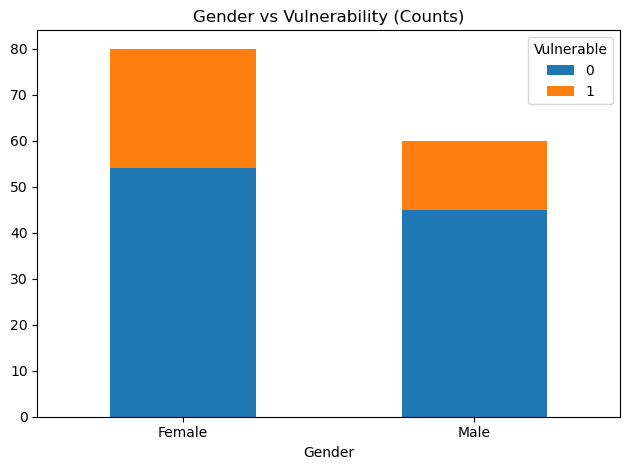

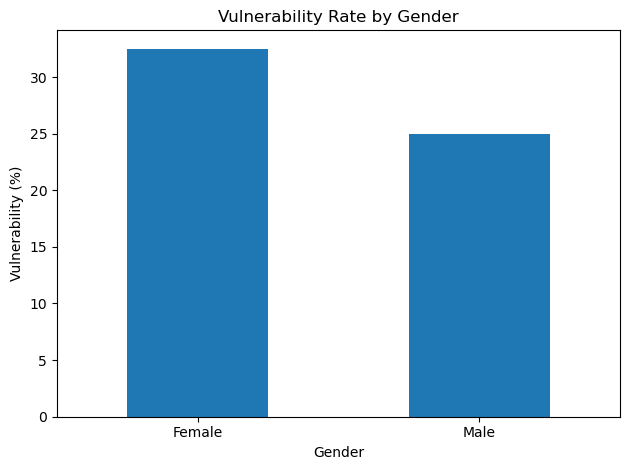

/var/folders/l4/5pw1zvn16fv694mg4r8n5v8c0000gn/T/ipykernel_78218/152126353.py:87: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([


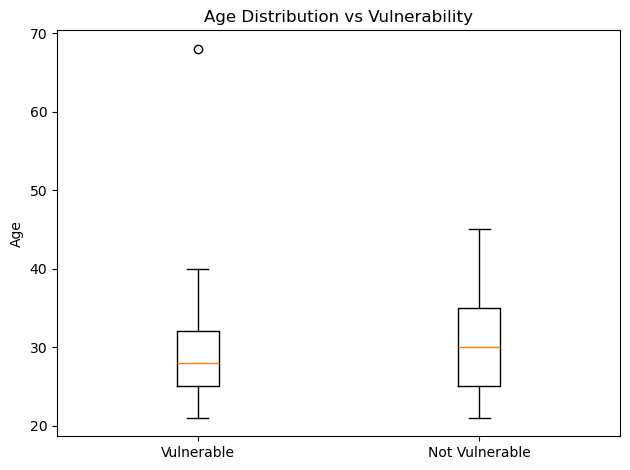

/var/folders/l4/5pw1zvn16fv694mg4r8n5v8c0000gn/T/ipykernel_78218/152126353.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(group_col)["Vulnerable"].mean() * 100


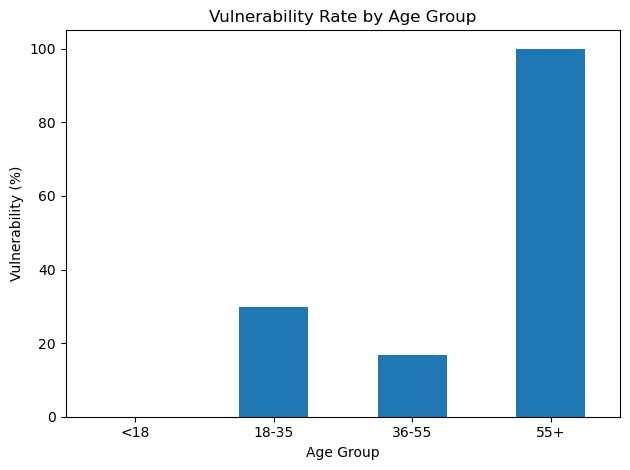

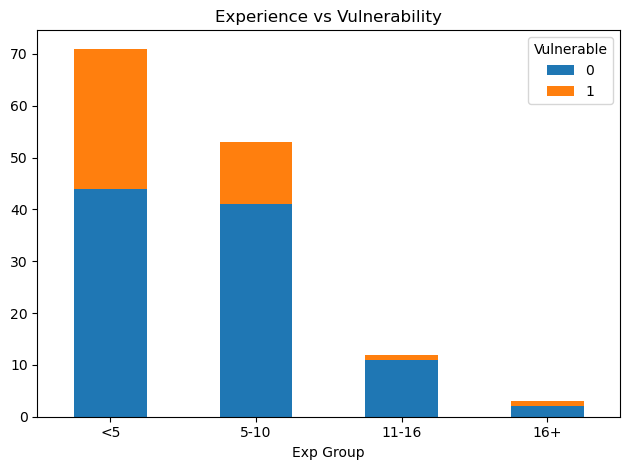

/var/folders/l4/5pw1zvn16fv694mg4r8n5v8c0000gn/T/ipykernel_78218/152126353.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(group_col)["Vulnerable"].mean() * 100


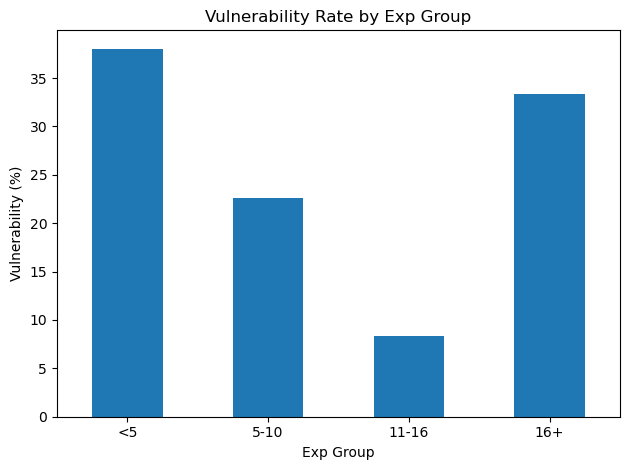

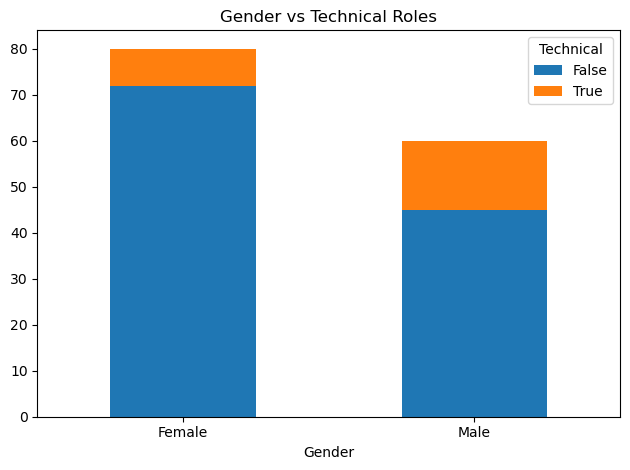

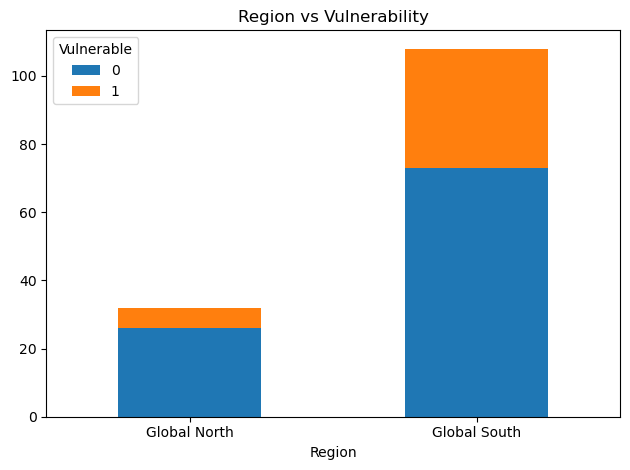

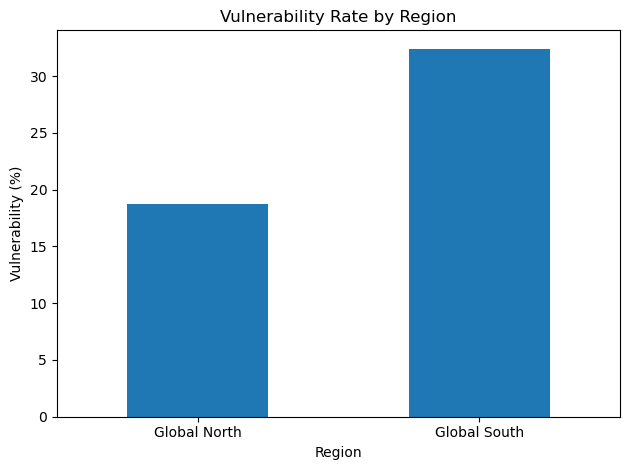

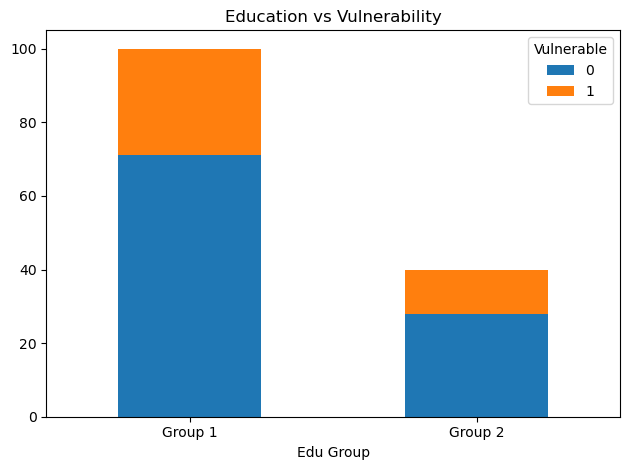

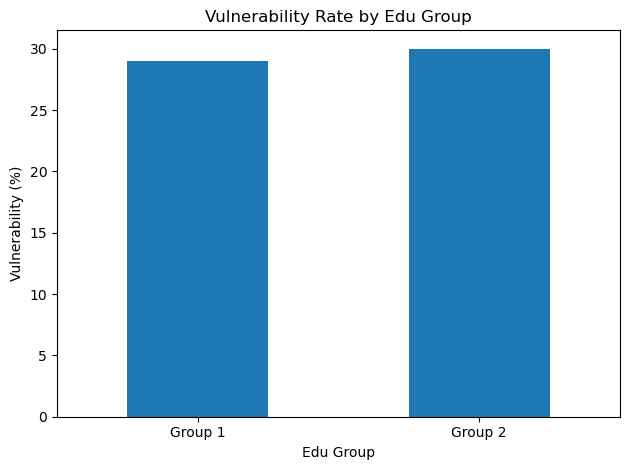

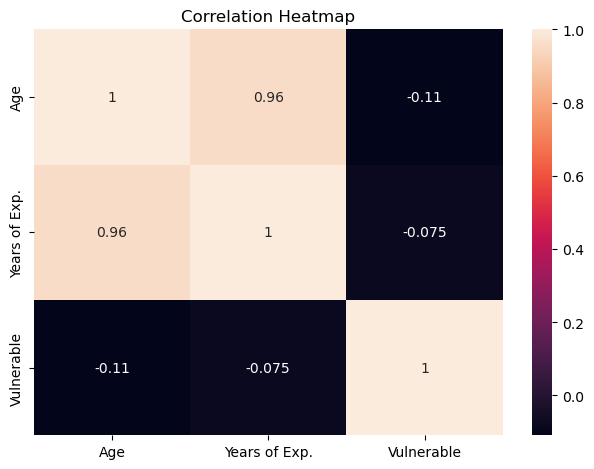

✅ All improved visualizations generated


In [37]:
# =============================
# CLEANING
# =============================

df["Gender"] = df["Gender"].astype(str).str.strip().str.lower()
df["Gender"] = df["Gender"].apply(
    lambda g: "Male" if "male" in g and "female" not in g else
              "Female" if "female" in g else "Other"
)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Years of Exp."] = pd.to_numeric(df["Years of Exp."], errors="coerce")
df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

df = df.dropna(subset=["Vulnerable"])

# =============================
# FEATURES
# =============================

tech_keywords = ["engineer", "developer", "data", "software", "analyst"]

df["Technical"] = df["Domain of work"].astype(str).str.lower().apply(
    lambda x: any(k in x for k in tech_keywords)
)

north = ["usa", "canada", "uk", "germany", "france", "japan", "singapore", "australia", "new zealand"]

df["Region"] = df["Location"].astype(str).str.lower().apply(
    lambda x: "Global North" if any(c in x for c in north) else "Global South"
)

# =============================
# GROUPING FUNCTIONS
# =============================

df["Age Group"] = pd.cut(df["Age"], bins=[0, 18, 35, 55, 100],
                         labels=["<18", "18-35", "36-55", "55+"])

df["Exp Group"] = pd.cut(df["Years of Exp."], bins=[0, 5, 10, 16, 100],
                         labels=["<5", "5-10", "11-16", "16+"])

df["Edu Group"] = df["Education Level"].astype(str).str.lower().apply(
    lambda x: "Group 2" if ("phd" in x or "master" in x or "msc" in x) else "Group 1"
)

# =========================================================
# 🔥 REUSABLE PLOTTING FUNCTIONS (IMPORTANT IMPROVEMENT)
# =========================================================

def plot_bar(data, title, xlabel, ylabel):
    data.plot(kind="bar")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

def plot_stacked_crosstab(x, y, title):
    pd.crosstab(df[x], df[y]).plot(kind="bar", stacked=True)
    plt.title(title)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

def plot_rate(group_col):
    rates = df.groupby(group_col)["Vulnerable"].mean() * 100
    rates.plot(kind="bar")
    plt.title(f"Vulnerability Rate by {group_col}")
    plt.ylabel("Vulnerability (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# =========================================================
# 📊 1. GENDER VS VULNERABILITY (STACKED + RATE)
# =========================================================

plot_stacked_crosstab("Gender", "Vulnerable", "Gender vs Vulnerability (Counts)")
plot_rate("Gender")

# =========================================================
# 📊 2. AGE ANALYSIS
# =========================================================

plt.boxplot([
    df[df["Vulnerable"] == 1]["Age"].dropna(),
    df[df["Vulnerable"] == 0]["Age"].dropna()
], labels=["Vulnerable", "Not Vulnerable"])

plt.title("Age Distribution vs Vulnerability")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

plot_rate("Age Group")

# =========================================================
# 📊 3. EXPERIENCE ANALYSIS
# =========================================================

plot_stacked_crosstab("Exp Group", "Vulnerable", "Experience vs Vulnerability")
plot_rate("Exp Group")

# =========================================================
# 📊 4. JOB BIAS
# =========================================================

plot_stacked_crosstab("Gender", "Technical", "Gender vs Technical Roles")

# =========================================================
# 📊 5. REGION BIAS
# =========================================================

plot_stacked_crosstab("Region", "Vulnerable", "Region vs Vulnerability")
plot_rate("Region")

# =========================================================
# 📊 6. EDUCATION BIAS
# =========================================================

plot_stacked_crosstab("Edu Group", "Vulnerable", "Education vs Vulnerability")
plot_rate("Edu Group")

# =========================================================
# 📊 7. BONUS (VERY HIGH VALUE): CORRELATION HEATMAP
# =========================================================

import seaborn as sns

numeric_df = df[["Age", "Years of Exp.", "Vulnerable"]].dropna()

plt.figure()
sns.heatmap(numeric_df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# =============================
print("✅ All improved visualizations generated")

# Model Bias (LLM comparison)


Valid Models Used:
Model
Meta-Llama-3-70B-Instruct       174
Meta-Llama-3-8B-Instruct        151
Meta-Llama-3.2-1B-Instruct      150
gemma-3-27b-it                   96
gemma-4-31B-it                   75
gemma-4-26B-A4B-it               42
Qwen2.5-7B-Instruct              39
Qwen2.5-Coder-7B-Instruct        36
DeepSeek-R1-Distill-Llama-8B     33
DeepSeek-R1-Distill-Qwen-7B      29
DeepSeek-R1-0528                 12
Kimi-K2-Thinking                  3
Name: count, dtype: int64

Model Vulnerability Rates:
Model
gemma-3-27b-it                  0.125000
Meta-Llama-3-8B-Instruct        0.198675
Meta-Llama-3.2-1B-Instruct      0.200000
gemma-4-31B-it                  0.213333
Meta-Llama-3-70B-Instruct       0.218391
gemma-4-26B-A4B-it              0.261905
DeepSeek-R1-0528                0.333333
Qwen2.5-7B-Instruct             0.333333
Qwen2.5-Coder-7B-Instruct       0.333333
DeepSeek-R1-Distill-Qwen-7B     0.344828
DeepSeek-R1-Distill-Llama-8B    0.363636
Name: Vulnerable, dtype: float6

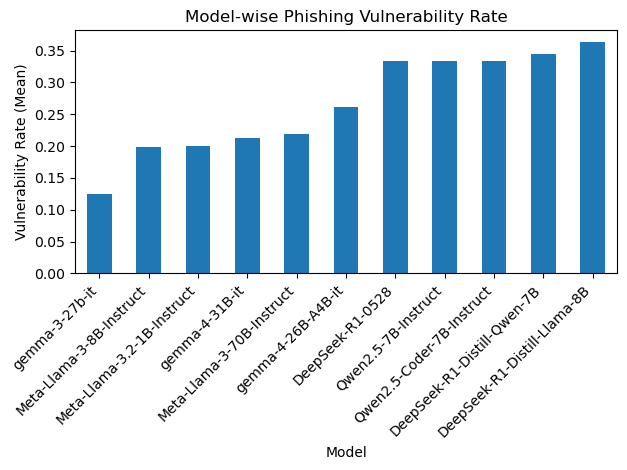


Gender Bias by Model:
Gender                          Female      Male
Model                                           
DeepSeek-R1-0528              0.285714  0.500000
DeepSeek-R1-Distill-Llama-8B  0.500000  0.181818
DeepSeek-R1-Distill-Qwen-7B   0.533333  0.090909
Meta-Llama-3-70B-Instruct     0.152778  0.051724
Meta-Llama-3-8B-Instruct      0.202703  0.163265
Meta-Llama-3.2-1B-Instruct    0.222222  0.169492
Qwen2.5-7B-Instruct           0.416667  0.142857
Qwen2.5-Coder-7B-Instruct     0.444444  0.266667
gemma-3-27b-it                0.230769  0.000000
gemma-4-26B-A4B-it            0.133333  0.285714
gemma-4-31B-it                0.200000  0.160000


<Figure size 640x480 with 0 Axes>

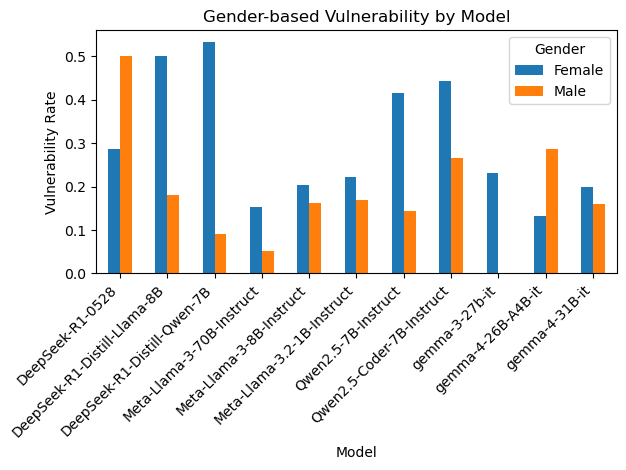


Gender Bias Gap (Male - Female):
Model
DeepSeek-R1-Distill-Qwen-7B    -0.442424
DeepSeek-R1-Distill-Llama-8B   -0.318182
Qwen2.5-7B-Instruct            -0.273810
gemma-3-27b-it                 -0.230769
Qwen2.5-Coder-7B-Instruct      -0.177778
Meta-Llama-3-70B-Instruct      -0.101054
Meta-Llama-3.2-1B-Instruct     -0.052731
gemma-4-31B-it                 -0.040000
Meta-Llama-3-8B-Instruct       -0.039437
gemma-4-26B-A4B-it              0.152381
DeepSeek-R1-0528                0.214286
dtype: float64


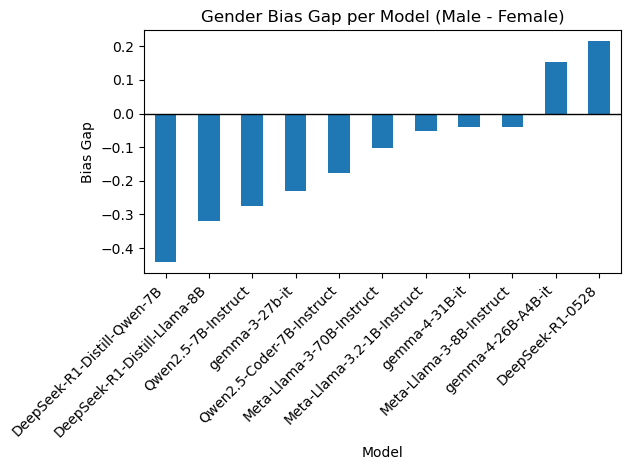

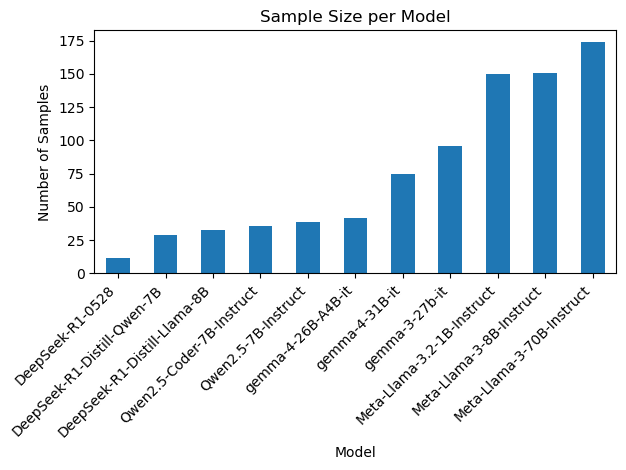


✅ Model bias analysis complete


In [30]:

# =============================
# CLEAN BASIC COLUMNS
# =============================

df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

df["Gender"] = df["Gender"].astype(str).str.strip().str.lower()
df["Gender"] = df["Gender"].apply(
    lambda g: "Male" if g in ["male", "m"] else
              "Female" if g in ["female", "f"] else "Other"
)

# =============================
# FILTER MODELS WITH >= 10 ROWS
# =============================

model_counts = df["Model"].value_counts()
valid_models = model_counts[model_counts >= 10].index

df = df[df["Model"].isin(valid_models)]

print("\nValid Models Used:")
print(model_counts[model_counts >= 0])

# =============================
# 1. OVERALL MODEL VULNERABILITY RATE
# =============================

model_vuln_rate = df.groupby("Model")["Vulnerable"].mean().sort_values()

print("\nModel Vulnerability Rates:")
print(model_vuln_rate)

plt.figure()

model_vuln_rate.plot(kind="bar")

plt.title("Model-wise Phishing Vulnerability Rate")
plt.xlabel("Model")
plt.ylabel("Vulnerability Rate (Mean)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# =============================
# 2. GENDER BIAS PER MODEL
# =============================

gender_model = df[df["Gender"].isin(["Male", "Female"])]

gender_bias = gender_model.groupby(["Model", "Gender"])["Vulnerable"].mean().unstack()

print("\nGender Bias by Model:")
print(gender_bias)

plt.figure()

gender_bias.plot(kind="bar")

plt.title("Gender-based Vulnerability by Model")
plt.xlabel("Model")
plt.ylabel("Vulnerability Rate")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Gender")

plt.tight_layout()
plt.show()

# =============================
# 3. GENDER DIFFERENCE (Male - Female gap)
# =============================

gender_gap = gender_bias["Male"] - gender_bias["Female"]

gender_gap = gender_gap.sort_values()

print("\nGender Bias Gap (Male - Female):")
print(gender_gap)

plt.figure()

gender_gap.plot(kind="bar")

plt.title("Gender Bias Gap per Model (Male - Female)")
plt.xlabel("Model")
plt.ylabel("Bias Gap")
plt.xticks(rotation=45, ha="right")

plt.axhline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

# =============================
# 4. SAMPLE SIZE PER MODEL (for transparency)
# =============================

plt.figure()

model_counts[model_counts >= 10].sort_values().plot(kind="bar")

plt.title("Sample Size per Model")
plt.xlabel("Model")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# =============================
# DONE
# =============================

print("\n✅ Model bias analysis complete")

# MODEL BIAS ANALYSIS

In [23]:
# =============================
# CLEAN VULNERABILITY
# =============================

df["Vulnerable"] = df["Phishing Susceptible (Y/N)"].map({"Y": 1, "N": 0})

# =============================
# ROBUST GENDER CLEANING
# =============================

def clean_gender(g):
    if pd.isna(g):
        return np.nan

    g = str(g).lower()
    g = re.sub(r"[*_.`]", "", g)

    if "male" in g and "female" not in g:
        return "Male"
    elif "female" in g:
        return "Female"
    else:
        return "Other"

df["Gender"] = df["Gender"].apply(clean_gender)

# =============================
# FILTER MODELS (≥ 10 samples)
# =============================

model_counts = df["Model"].value_counts()
valid_models = model_counts[model_counts >= 10].index

df = df[df["Model"].isin(valid_models)]

print("\n================ VALID MODELS ================\n")
print(model_counts[model_counts >= 10])

# =============================
# BASIC SANITY CHECKS (IMPORTANT IMPROVEMENT)
# =============================

print("\nMissing values check:")
print(df[["Model", "Gender", "Vulnerable"]].isnull().sum())

print("\nFinal dataset size:", len(df))


================ VALID MODELS ================

Model
Meta-Llama-3-70B-Instruct       174
Meta-Llama-3-8B-Instruct        151
Meta-Llama-3.2-1B-Instruct      150
gemma-3-27b-it                   96
gemma-4-31B-it                   75
gemma-4-26B-A4B-it               42
Qwen2.5-7B-Instruct              39
Qwen2.5-Coder-7B-Instruct        36
DeepSeek-R1-Distill-Llama-8B     33
DeepSeek-R1-Distill-Qwen-7B      29
DeepSeek-R1-0528                 12
Name: count, dtype: int64

Missing values check:
Model         0
Gender        0
Vulnerable    0
dtype: int64

Final dataset size: 837


In [24]:
# =========================================================
# MODEL vs VULNERABILITY (CHI-SQUARE + EFFECT SIZE)
# =========================================================

print("\n================ MODEL vs VULNERABILITY =================\n")

model_table = pd.crosstab(df["Model"], df["Vulnerable"])

print("Contingency Table:")
print(model_table)

# -----------------------------
# CHI-SQUARE TEST
# -----------------------------

chi2, p, dof, expected = chi2_contingency(model_table)

print(f"\nChi-square result:")
print(f"χ²({dof}, N={len(df)}) = {chi2:.3f}, p = {p:.6f}")

# -----------------------------
# EFFECT SIZE (CRAMER'S V)
# -----------------------------

n = model_table.to_numpy().sum()
min_dim = min(model_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"\nCramér's V = {cramers_v:.4f}")

# -----------------------------
# ASSUMPTION CHECK (IMPORTANT)
# -----------------------------

if (expected < 5).any():
    print("\n⚠ Warning: Some expected frequencies are below 5 (chi-square assumption may be weak).")

# -----------------------------
# MODEL-LEVEL BIAS INSIGHT
# -----------------------------

model_rates = df.groupby("Model")["Vulnerable"].mean().sort_values()

print("\nVulnerability Rate per Model:")
print(model_rates)

print("\nInterpretation:")

if p < 0.05:
    print("- Significant differences exist between models in phishing vulnerability predictions.")
else:
    print("- No statistically significant differences between models.")


================ MODEL vs VULNERABILITY =================

Contingency Table:
Vulnerable                      0   1
Model                                
DeepSeek-R1-0528                8   4
DeepSeek-R1-Distill-Llama-8B   21  12
DeepSeek-R1-Distill-Qwen-7B    19  10
Meta-Llama-3-70B-Instruct     136  38
Meta-Llama-3-8B-Instruct      121  30
Meta-Llama-3.2-1B-Instruct    120  30
Qwen2.5-7B-Instruct            26  13
Qwen2.5-Coder-7B-Instruct      24  12
gemma-3-27b-it                 84  12
gemma-4-26B-A4B-it             31  11
gemma-4-31B-it                 59  16

Chi-square result:
χ²(10, N=837) = 18.977, p = 0.040562

Cramér's V = 0.1506

⚠ Warning: Some expected frequencies are below 5 (chi-square assumption may be weak).

Vulnerability Rate per Model:
Model
gemma-3-27b-it                  0.125000
Meta-Llama-3-8B-Instruct        0.198675
Meta-Llama-3.2-1B-Instruct      0.200000
gemma-4-31B-it                  0.213333
Meta-Llama-3-70B-Instruct       0.218391
gemma-4-26B-A4B-it  

In [25]:
# =========================================================
# 1. MODEL vs VULNERABILITY
# =========================================================

print("\n================ MODEL vs VULNERABILITY =================\n")

model_table = pd.crosstab(df["Model"], df["Vulnerable"])
print(model_table)

chi2, p, dof, expected = chi2_contingency(model_table)

# Effect size
n = model_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(model_table.shape) - 1)))

print(f"\nχ²({dof}, N={len(df)}) = {chi2:.3f}")
print(f"p-value = {p:.6f}")
print(f"Cramér's V = {cramers_v:.4f}")

# =========================================================
# 2. MODEL × GENDER × VULNERABILITY
# =========================================================

print("\n================ MODEL × GENDER INTERACTION ================\n")

gender_df = df[df["Gender"].isin(["Male", "Female"])]

interaction_table = pd.crosstab(
    [gender_df["Model"], gender_df["Gender"]],
    gender_df["Vulnerable"]
)

print(interaction_table)

chi2_g, p_g, dof_g, expected_g = chi2_contingency(interaction_table)

# Effect size
n_g = interaction_table.to_numpy().sum()
cramers_v_g = np.sqrt(chi2_g / (n_g * (min(interaction_table.shape) - 1)))

print(f"\nχ²({dof_g}, N={n_g}) = {chi2_g:.3f}")
print(f"p-value = {p_g:.6f}")
print(f"Cramér's V = {cramers_v_g:.4f}")

# =========================================================
# 3. MODEL-LEVEL INTERPRETATION (VERY IMPORTANT)
# =========================================================

print("\n================ INTERPRETATION =================\n")

model_rates = df.groupby("Model")["Vulnerable"].mean().sort_values()

print("Vulnerability rate per model:")
print(model_rates)

if p < 0.05:
    print("\n- Significant differences exist across models.")
else:
    print("\n- No significant difference across models.")

if p_g < 0.05:
    print("- Gender interaction effect is significant across models.")
else:
    print("- No strong gender interaction effect detected across models.")


================ MODEL vs VULNERABILITY =================

Vulnerable                      0   1
Model                                
DeepSeek-R1-0528                8   4
DeepSeek-R1-Distill-Llama-8B   21  12
DeepSeek-R1-Distill-Qwen-7B    19  10
Meta-Llama-3-70B-Instruct     136  38
Meta-Llama-3-8B-Instruct      121  30
Meta-Llama-3.2-1B-Instruct    120  30
Qwen2.5-7B-Instruct            26  13
Qwen2.5-Coder-7B-Instruct      24  12
gemma-3-27b-it                 84  12
gemma-4-26B-A4B-it             31  11
gemma-4-31B-it                 59  16

χ²(10, N=837) = 18.977
p-value = 0.040562
Cramér's V = 0.1506

================ MODEL × GENDER INTERACTION ================

Vulnerable                            0   1
Model                        Gender        
DeepSeek-R1-0528             Female   5   2
                             Male     2   2
DeepSeek-R1-Distill-Llama-8B Female   9   9
                             Male     9   2
DeepSeek-R1-Distill-Qwen-7B  Female   7   8
            

In [28]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

# =========================================================
# PAIRWISE MODEL COMPARISON (Z-TEST + EFFECT SIZE)
# =========================================================

print("\n================ PAIRWISE MODEL COMPARISONS ================\n")

results = []

models = df["Model"].unique()

for m1, m2 in itertools.combinations(models, 2):

    d1 = df[df["Model"] == m1]["Vulnerable"]
    d2 = df[df["Model"] == m2]["Vulnerable"]

    # skip small samples
    if len(d1) < 10 or len(d2) < 10:
        continue

    count = [d1.sum(), d2.sum()]
    nobs = [len(d1), len(d2)]

    stat, pval = proportions_ztest(count, nobs)

    # effect size (difference in proportions)
    prop_diff = (d1.mean() - d2.mean())

    results.append([m1, m2, stat, pval, prop_diff])

pairwise_df = pd.DataFrame(
    results,
    columns=["Model 1", "Model 2", "Z-score", "p-value", "Mean Difference"]
)

# =========================================================
# MULTIPLE TEST CORRECTION (IMPORTANT)
# =========================================================

pairwise_df["adjusted_p"] = multipletests(
    pairwise_df["p-value"],
    method="bonferroni"
)[1]

# =========================================================
# SORT RESULTS
# =========================================================

pairwise_df = pairwise_df.sort_values("adjusted_p")

print(pairwise_df)


================ PAIRWISE MODEL COMPARISONS ================

                         Model 1                      Model 2   Z-score  \
3   DeepSeek-R1-Distill-Llama-8B               gemma-3-27b-it  3.038952   
39                gemma-3-27b-it          Qwen2.5-7B-Instruct -2.824407   
38                gemma-3-27b-it    Qwen2.5-Coder-7B-Instruct -2.763854   
12   DeepSeek-R1-Distill-Qwen-7B               gemma-3-27b-it  2.724218   
0   DeepSeek-R1-Distill-Llama-8B  DeepSeek-R1-Distill-Qwen-7B  0.154444   
30                gemma-4-31B-it     Meta-Llama-3-8B-Instruct  0.257708   
31                gemma-4-31B-it    Meta-Llama-3-70B-Instruct -0.088843   
32                gemma-4-31B-it    Qwen2.5-Coder-7B-Instruct -1.362720   
33                gemma-4-31B-it          Qwen2.5-7B-Instruct -1.395687   
34                gemma-3-27b-it           gemma-4-26B-A4B-it -1.985663   
35                gemma-3-27b-it   Meta-Llama-3.2-1B-Instruct -1.525002   
36                gemma-3-27b-it     

In [29]:
# =========================================================
# EFFECT SIZE (CRAMER'S V)
# =========================================================

print("\n================ EFFECT SIZE (CRAMER'S V) ================\n")

# Safety check
if model_table.shape[0] < 2 or model_table.shape[1] < 2:
    print("Cramér's V cannot be computed (insufficient categories).")
else:

    n = model_table.to_numpy().sum()
    chi2_val = chi2  # ensure clarity from previous test

    min_dim = min(model_table.shape) - 1

    # avoid division by zero
    if min_dim == 0:
        cramers_v = 0
    else:
        cramers_v = np.sqrt(chi2_val / (n * min_dim))

    print(f"Cramér's V = {cramers_v:.4f}")

    # =============================
    # EFFECT SIZE INTERPRETATION
    # =============================

    if cramers_v < 0.1:
        strength = "negligible"
    elif cramers_v < 0.3:
        strength = "weak"
    elif cramers_v < 0.5:
        strength = "moderate"
    else:
        strength = "strong"

    print(f"Effect size interpretation: {strength}")

    # =============================
    # BIAS INTERPRETATION CONTEXT
    # =============================

    print("\nInterpretation:")

    if strength in ["moderate", "strong"]:
        print("- Model bias is practically meaningful, not just statistically significant.")
    else:
        print("- Model differences are small in practical terms.")


================ EFFECT SIZE (CRAMER'S V) ================

Cramér's V = 0.1754
Effect size interpretation: weak

Interpretation:
- Model differences are small in practical terms.
